# LAB 03 — Nhận dạng tiếng nói nâng cao với HMM
**CSE457 · Xử lý âm thanh và tiếng nói**

## Phạm vi và tính trung thực của dữ liệu
Đây là bài thực hành chạy đầy đủ bằng **âm thanh tiếng Việt tổng hợp eSpeak NG**, không phải các utterance của người nói thật. 5 lệnh: mở, đóng, lên, xuống, dừng; 30 train + 10 test. Bộ dữ liệu, mã, kết quả và báo cáo nằm trong cùng dự án.

Lexicon và corpus tự xây để minh họa; chưa được giảng viên xác nhận. Để nộp theo yêu cầu dữ liệu người thật, dùng hướng dẫn thu âm trong README rồi chạy lại. Không suy diễn accuracy demo thành hiệu quả ASR thực tế.

**Chạy:** chọn Python kernel đã cài `requirements.txt`, mở notebook từ thư mục dự án và Run All. Các phép tính nằm trong `lab3.py` để dễ kiểm thử và quản lý Git. Thay DATA/OUTPUT ở cell sau nếu có bộ ghi âm riêng.

In [1]:
from pathlib import Path
import csv, json, html
import numpy as np
from IPython.display import display, HTML, Image, Markdown, Audio
from threadpoolctl import threadpool_limits
from lab3 import run, LABELS, parse_lexicon, log_forward_viterbi

DATA = Path('dataset_demo')
OUTPUT = Path('results_demo')
assert DATA.exists(), 'Mở notebook từ thư mục Lab03_HMM hoặc sửa DATA.'

def table(name):
    with (OUTPUT/name).open(encoding='utf-8-sig', newline='') as f:
        rows=list(csv.DictReader(f))
    if not rows:
        print('Không có dòng dữ liệu.'); return
    columns=list(rows[0])
    body='<tr>'+''.join('<th>'+html.escape(c)+'</th>' for c in columns)+'</tr>'
    for row in rows:
        body+='<tr>'+''.join('<td>'+html.escape(str(row[c]))+'</td>' for c in columns)+'</tr>'
    display(HTML('<div style="overflow-x:auto"><table>'+body+'</table></div>'))

def figure(name):
    display(Image(filename=str(OUTPUT/'figures'/name), width=740))

print('Nguồn dữ liệu:', DATA)
provenance=DATA/'PROVENANCE.json'
if provenance.exists():
    print(json.loads(provenance.read_text(encoding='utf-8'))['description'])


Nguồn dữ liệu: dataset_demo
40 separate syntheses; shared engine/voice across splits. NOT independent human speakers. Accuracy only demonstrates software.


## A. Dữ liệu và đặc trưng 39 chiều
Đọc WAV → mono/resample 16 kHz → cắt silence tương đối 30 dB → pre-emphasis 0.97 → MFCC (Hamming 25 ms, hop 10 ms, FFT 512, 26 mel filters, 13 hệ số) → delta và delta-delta → CMVN từng utterance.

Mỗi vector có 13 + 13 + 13 = 39 chiều. CMVN dùng chính utterance đang xử lý, không thu thống kê test để fit train. Kiểm tra hash của waveform phát hiện mẫu trùng kể cả khác metadata. Các biến thể tổng hợp vẫn dùng chung một nguồn voice, vì thế chưa phải speaker-independent.

Cell sau thực hiện toàn bộ thí nghiệm một lần; các mục kế tiếp đọc lại kết quả để trình bày.

In [2]:
with threadpool_limits(limits=1):
    summary = run(DATA, OUTPUT)
assert summary['train_files'] >= 30 and summary['test_files'] >= 10


Dataset: dataset_demo | SYNTHETIC DEMO
Training E1 and E2 (fixed settings; validation separated)...
Main model topology:
mo 
 [[0.882 0.118 0.    0.    0.   ]
 [0.    0.818 0.182 0.    0.   ]
 [0.    0.    0.903 0.097 0.   ]
 [0.    0.    0.    0.87  0.13 ]
 [0.    0.    0.    0.    1.   ]]
dong 
 [[0.812 0.188 0.    0.    0.   ]
 [0.    0.667 0.333 0.    0.   ]
 [0.    0.    0.727 0.273 0.   ]
 [0.    0.    0.    0.842 0.158]
 [0.    0.    0.    0.    1.   ]]
len 
 [[0.867 0.133 0.    0.    0.   ]
 [0.    0.786 0.214 0.    0.   ]
 [0.    0.    0.85  0.15  0.   ]
 [0.    0.    0.    0.833 0.167]
 [0.    0.    0.    0.    1.   ]]
xuong 
 [[0.875 0.125 0.    0.    0.   ]
 [0.    0.87  0.13  0.    0.   ]
 [0.    0.    0.829 0.171 0.   ]
 [0.    0.    0.    0.905 0.095]
 [0.    0.    0.    0.    1.   ]]
dung 
 [[0.857 0.143 0.    0.    0.   ]
 [0.    0.854 0.146 0.    0.   ]
 [0.    0.    0.85  0.15  0.   ]
 [0.    0.    0.    0.864 0.136]
 [0.    0.    0.    0.    1.   ]]
DTW baseline and

Model is not converging.  Current: -5009.945476120832 is not greater than -5009.945459709094. Delta is -1.6411737306043506e-05
Model is not converging.  Current: -6243.768573522251 is not greater than -6243.7685130780155. Delta is -6.0444235714385286e-05
Model is not converging.  Current: -2509.609485617357 is not greater than -2509.6093816507428. Delta is -0.00010396661446065991
Model is not converging.  Current: -1919.750763112469 is not greater than -1919.7504966310935. Delta is -0.00026648137554730056
Model is not converging.  Current: -3751.5195182736734 is not greater than -3751.519517945295. Delta is -3.283785190433264e-07
Model is not converging.  Current: -2233.7570064391543 is not greater than -2233.7569058129416. Delta is -0.00010062621277029393
Model is not converging.  Current: -611.89763626593 is not greater than -611.8976361851807. Delta is -8.074937341007171e-08
Model is not converging.  Current: -757.7437973979772 is not greater than -757.7437725431948. Delta is -2.485

path,split,label,waveform_sha256,source_sr,source_channels,source_subtype,seconds
dataset_demo\train\mo\mo_01.wav,train,mo,5c0a8f7e8fdf13ebbd0da471b0f9c29b746db86f3e79ea9afd22bef5c726432d,16000,1,PCM_16,0.9585
dataset_demo\train\mo\mo_02.wav,train,mo,ef217b33a96f80caadfe7c81562639cde56cf26c9a9dddd79f9bc798e400f041,16000,1,PCM_16,0.9065
dataset_demo\train\mo\mo_03.wav,train,mo,ca6ca9f222264e0e71ee90e9dffd27e353f94519b882f28a0821189879247696,16000,1,PCM_16,0.862375
dataset_demo\train\mo\mo_04.wav,train,mo,35712f4a3a4100a8b458bdd0ff830c66726d82669531f54fd141628945afe0cc,16000,1,PCM_16,0.821
dataset_demo\train\mo\mo_05.wav,train,mo,f61f5dbd07b25eb40e1b1ae63e94d2e610bd2a2606a84987b627a6ee61feec8b,16000,1,PCM_16,0.7986875
dataset_demo\train\mo\mo_06.wav,train,mo,220e09d272942edecafdc34a2068057b171a6cb9b6ef27a5bc0e1cce9c7f5177,16000,1,PCM_16,0.76375
dataset_demo\train\dong\dong_01.wav,train,dong,9aa10c573b617de48d4a7a319617c808f3443c34d016e5c4eb96d4d73b019a48,16000,1,PCM_16,0.769125
dataset_demo\train\dong\dong_02.wav,train,dong,e50cf7763b88d69cf62c72fdb9b0f6469d2fa8c876c48819602437010ec5f8c2,16000,1,PCM_16,0.75
dataset_demo\train\dong\dong_03.wav,train,dong,0c13c4a6a309cc642490ba3fa63c192575949b425aff4276aa93b5bce65cdd0d,16000,1,PCM_16,0.728125
dataset_demo\train\dong\dong_04.wav,train,dong,a2fbadd1588b3acdc0b6d9b4c7ce7c11efb94514bdfa784d99f31cf7a811cf71,16000,1,PCM_16,0.71375


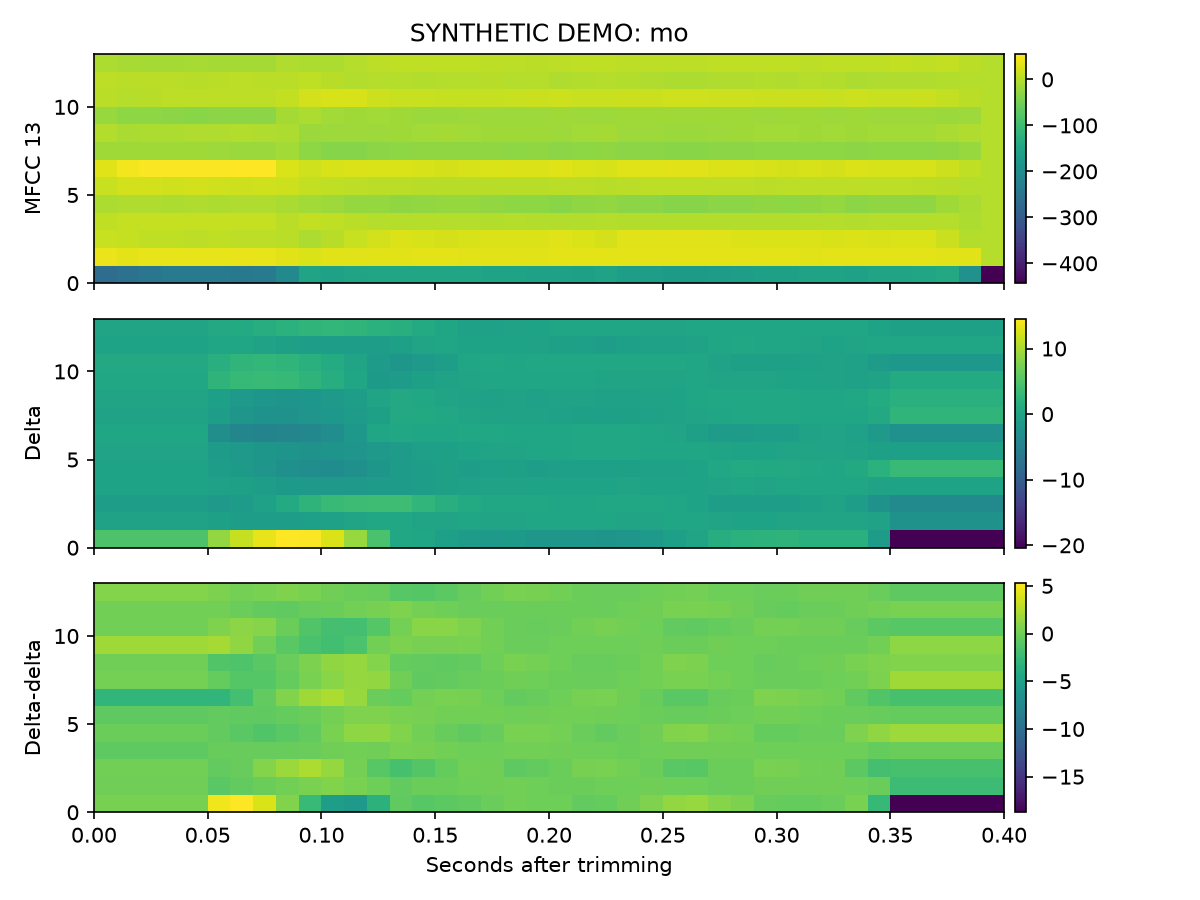

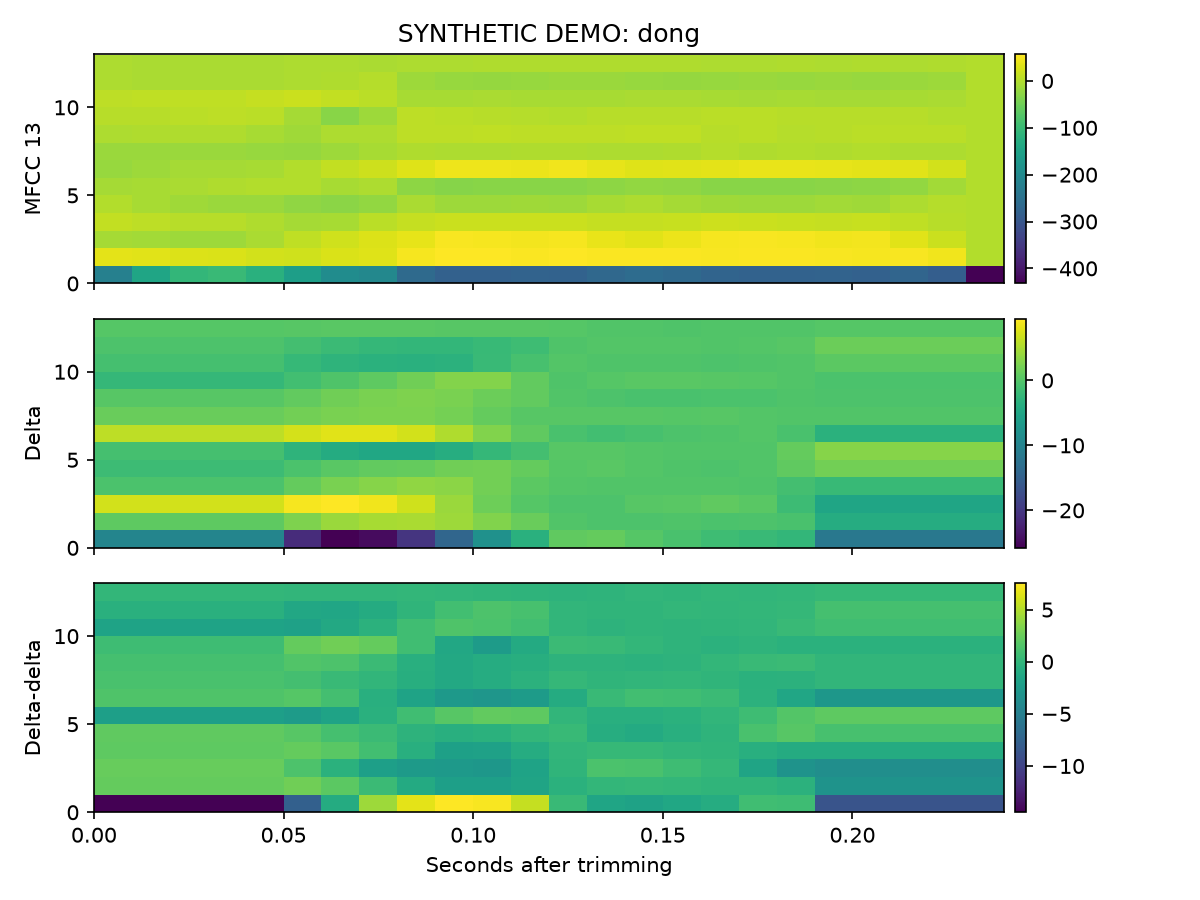

In [3]:
table('data_audit.csv')
figure('features_mo.png')
figure('features_dong.png')


Heatmap MFCC mô tả phổ ngắn hạn, delta/delta-delta làm nổi các vùng biến đổi theo thời gian. Các hình trước CMVN dùng dải màu riêng nên không so cường độ giữa các panel bằng màu đơn thuần. Từ “mở” và “đóng” tạo các đường biến đổi khác nhau; không gán một vùng heatmap thành phone khi chưa có nhãn phone.

## B–C. HMM trái-sang-phải và Baum–Welch
Mỗi từ có một HMM 5 state. π = [1, 0, 0, 0, 0]. Ban đầu A có self-loop 0.7, next-state 0.3, state cuối self-loop 1. Chỉ cập nhật transition và emission; giữ π cố định. Trung bình/phương sai khởi tạo từ các đoạn thời gian tương ứng trong train.

Fit nối utterance và truyền `lengths` để không tạo chuyển trạng thái qua ranh giới hai file. Gaussian diagonal: 39 phương sai/state so với 780 thành phần độc lập của covariance full. Baum–Welch do `hmmlearn` thực hiện; floor phương sai 0.01 sau M-step để tránh phương sai sụp.

`monitor.converged` có thể đúng khi đã chạm giới hạn hoặc gain âm; phải xem lịch sử, final_gain, số lần giảm objective. Floor có thể làm objective không đơn điệu hoàn toàn.

mo π = [1. 0. 0. 0. 0.]
[[0.882 0.118 0.    0.    0.   ]
 [0.    0.818 0.182 0.    0.   ]
 [0.    0.    0.903 0.097 0.   ]
 [0.    0.    0.    0.87  0.13 ]
 [0.    0.    0.    0.    1.   ]]
dong π = [1. 0. 0. 0. 0.]
[[0.812 0.188 0.    0.    0.   ]
 [0.    0.667 0.333 0.    0.   ]
 [0.    0.    0.727 0.273 0.   ]
 [0.    0.    0.    0.842 0.158]
 [0.    0.    0.    0.    1.   ]]
len π = [1. 0. 0. 0. 0.]
[[0.867 0.133 0.    0.    0.   ]
 [0.    0.786 0.214 0.    0.   ]
 [0.    0.    0.85  0.15  0.   ]
 [0.    0.    0.    0.833 0.167]
 [0.    0.    0.    0.    1.   ]]
xuong π = [1. 0. 0. 0. 0.]
[[0.875 0.125 0.    0.    0.   ]
 [0.    0.87  0.13  0.    0.   ]
 [0.    0.    0.829 0.171 0.   ]
 [0.    0.    0.    0.905 0.095]
 [0.    0.    0.    0.    1.   ]]
dung π = [1. 0. 0. 0. 0.]
[[0.857 0.143 0.    0.    0.   ]
 [0.    0.854 0.146 0.    0.   ]
 [0.    0.    0.85  0.15  0.   ]
 [0.    0.    0.    0.864 0.136]
 [0.    0.    0.    0.    1.   ]]
mo {'iterations': 7, 'monitor_converged': 

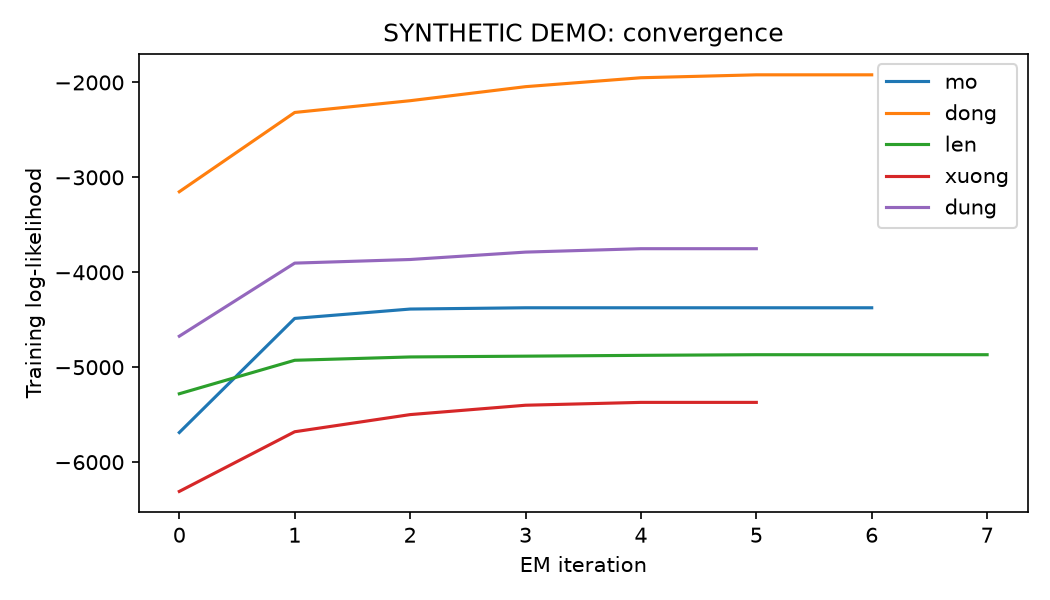

In [4]:
for label in LABELS:
    with np.load(OUTPUT/'models'/f'{label}.npz') as m:
        print(label, 'π =', m['startprob'])
        print(np.round(m['transmat'], 3))
figure('convergence.png')
monitors=json.loads((OUTPUT/'convergence.json').read_text(encoding='utf-8'))['5state_39dim']
for label,m in monitors.items():
    print(label, {k:v for k,v in m.items() if k not in ('history','warnings')})


## D. Likelihood, Forward và Viterbi
Forward cộng xác suất mọi đường state (logsumexp trong miền log); Viterbi lấy max và truy vết backpointer. Vì vậy log P(X) ≥ log P(X,Q*). Cả hai trong bài cho phép kết thúc ở bất kỳ state nào, nhất quán với `hmmlearn`; không ép kết thúc state cuối.

Nhận dạng chọn model có log-likelihood cao nhất trên **cùng** utterance. Chia cho T không đổi argmax. Score/frame dùng để xem phân bố khác độ dài hoặc re-ranking.

Bảng dưới có 3 utterance thuộc 3 lớp, score cả 5 model và margin top-1/top-2. Hai Viterbi path được đối chiếu với DP độc lập.

file,truth,prediction,frames,margin_per_frame,mo,dong,len,xuong,dung
mo_01.wav,mo,mo,40,109.87345548949216,-800.000756436489,-14032.290289557403,-6156.192943138688,-5194.938976016175,-6889.996307846445
dong_01.wav,dong,dong,24,100.01050929545083,-3801.0226667654097,-266.23951737000203,-3188.7556209393815,-2666.491740460822,-3086.2440955849966
len_01.wav,len,len,32,101.02364889375569,-5012.051320377555,-10905.861480565976,-824.2312703400117,-4056.9880349401938,-5458.955881558618


label,forward,viterbi,gap
mo,-800.0007564364887,-800.0018957385745,0.0011393020857894953
dong,-266.2395173700019,-266.23951738365514,1.3653220776177477e-08


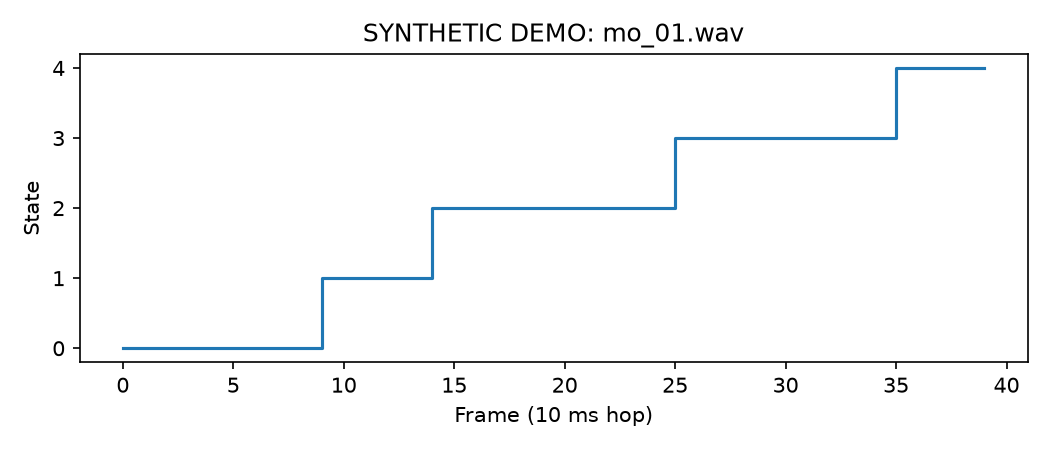

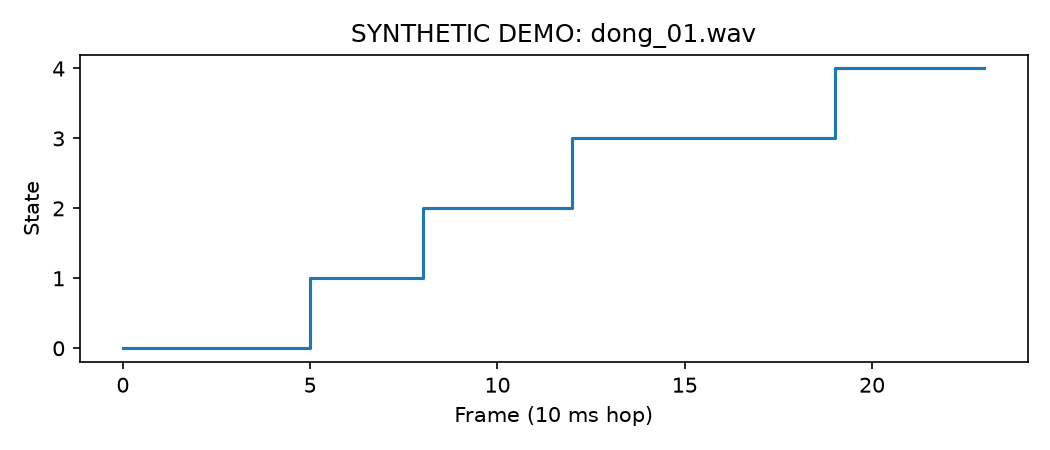

label,state,frames,approx_duration_ms
mo,0,9,90
mo,1,5,50
mo,2,11,110
mo,3,10,100
mo,4,5,50
dong,0,5,50
dong,1,3,30
dong,2,4,40
dong,3,7,70
dong,4,5,50


In [5]:
table('likelihood_examples.csv')
table('forward_viterbi.csv')
figure('viterbi_mo.png')
figure('viterbi_dong.png')
table('state_durations.csv')


State path không giảm; self-loop biểu diễn đoạn kéo dài. Duration xấp xỉ số frame × 10 ms, không phải ranh giới âm vị đã được gán nhãn. Các state là vùng âm học tiềm ẩn, không mặc định mỗi state là một phoneme.

## E. DTW baseline và các thí nghiệm E1–E4
Baseline MFCC13+DTW dùng toàn bộ 6 template/lớp, cùng split và tiền xử lý. Chi phí DTW là tổng khoảng cách Euclidean tối thiểu chia T+U; thêm DTW39 để đối chiếu cùng số chiều. Không có mã Lab 2 nên baseline được cài lại và công bố rõ quy ước.

E1 thử 3/5/7 state. E2 so 13D với 39D ở 5 state. Inner-validation lấy 2 file cuối/lớp từ train; model chính luôn cố định 5-state/39D trước test. E3 bỏ full covariance theo điều kiện “nếu đủ data” của đề. E4 so accuracy, confusion, thời gian score và 1/3/6 mẫu train/lớp.

states,dimensions,train_accuracy,validation_accuracy,test_accuracy,train_seconds,test_ms_per_trial,hit_iteration_limit,objective_decreases
3,39,1.0,1.0,1.0,0.0374627999999575,0.5452599999443919,0,0
5,39,1.0,1.0,1.0,0.040040299999418494,0.6725600000208942,0,1
7,39,1.0,1.0,1.0,0.05803990000003978,0.6489200000032724,0,2
5,13,1.0,1.0,1.0,0.06020059999991645,0.5882600000404636,0,1


method,accuracy,train_samples_per_class,train_seconds,test_ms_per_trial
HMM39,1.0,6,0.040040299999418494,0.6725600000208942
DTW13,1.0,6,0.0,1.9596999999521358
DTW39,1.0,6,0.0,2.207020000059856


samples_per_class,hmm_accuracy,dtw_accuracy
1,0.9,1.0
3,1.0,1.0
6,1.0,1.0


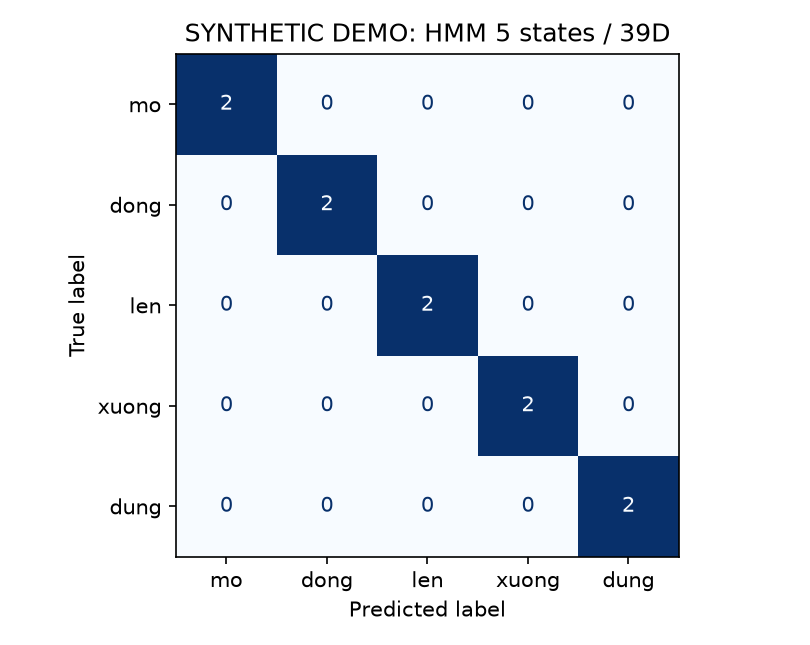

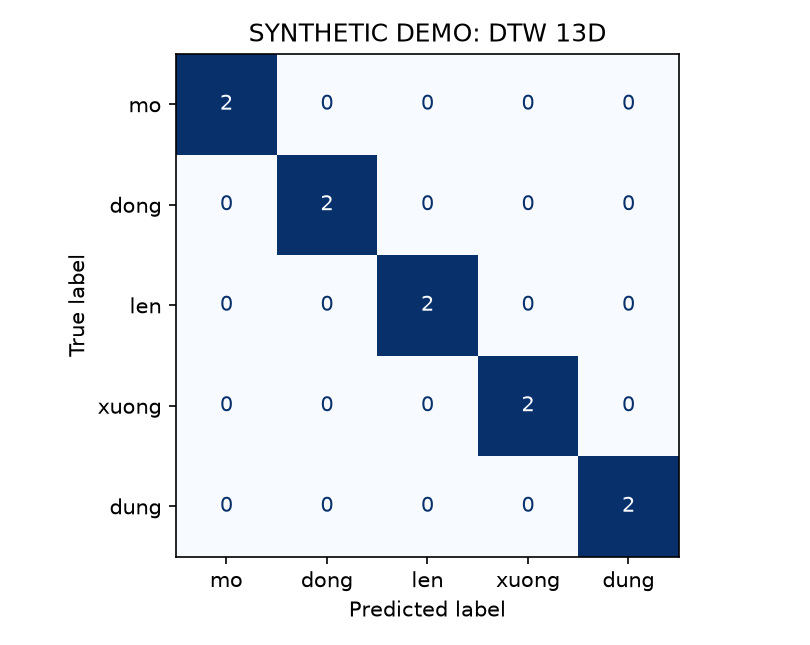

In [6]:
table('experiments.csv')
table('comparison.csv')
table('learning_curve.csv')
figure('cm_5state_39dim.png')
figure('cm_dtw13.png')


## F. Lexicon mini
`lexicon.txt` dùng format WORD PHONE_1 ... PHONE_K. Bản hiện tại là **inventory minh họa tự đặt**, có tone tags, không phải chuẩn phiên âm hay inventory của giảng viên. Parser kiểm tra dòng lỗi, trùng từ và thiếu nhãn.

Whole-word HMM đã có model cho mỗi từ nên không cần lexicon để decode. Với phone HMM, lexicon quyết định thứ tự nối các model phone để tạo word HMM, nối exit của phone trước sang entry của phone sau. Chưa huấn luyện phone model trong bài cơ bản.

In [7]:
display(parse_lexicon('lexicon.txt'))

{'mo': ['m', 'o_oh', 'T_HOI'],
 'dong': ['d', 'o_closed', 'ng', 'T_SAC'],
 'len': ['l', 'e_closed', 'n', 'T_NGANG'],
 'xuong': ['s', 'u_open', 'o_open', 'ng', 'T_SAC'],
 'dung': ['z', 'u_open', 'ng', 'T_HUYEN']}

## G. Unigram, bigram và re-ranking (E6)
Corpus nhỏ được tự xây trước khi đánh giá. Add-k với k=0.5, vocab 5 lệnh, không có EOS. Mẫu số dùng **số transition đi ra** từ previous word, tránh sai khi từ xuất hiện cuối câu.

Re-ranking: acoustic log-likelihood/frame + λ × log P(word|previous), λ ∈ {0, 0.1, 0.3, 1.0}. Đây là điểm có trọng số để minh họa, không phải MAP nguyên bản với tổng acoustic likelihood. Chọn utterance có margin nhỏ nhất trong điều kiện clean/noise đã định trước; không chọn theo đáp án.

Các previous-word context là giả định vì bộ isolated-word không có ngữ cảnh thật. Bảng không được dùng để báo accuracy LM. Bảng `lm_controlled_example` là điểm âm học giả lập gần nhau, tách biệt hoàn toàn với kết quả WAV: prior có thể giúp hoặc làm sai tùy nhãn thật.

In [8]:
display(json.loads((OUTPUT/'language_model.json').read_text(encoding='utf-8')))
table('lm_reranking.csv')
print('Ví dụ có kiểm soát: acoustic scores giả lập, KHÔNG tính vào accuracy')
table('lm_controlled_example.csv')


Ví dụ có kiểm soát: acoustic scores giả lập, KHÔNG tính vào accuracy


{'unigram': {'mo': 8, 'len': 9, 'dung': 13, 'xuong': 5, 'dong': 5},
 'outgoing': {'<s>': 14, 'mo': 7, 'len': 8, 'xuong': 5, 'dung': 4, 'dong': 2},
 'bigram': [{'previous': '<s>', 'current': 'dong', 'count': 2},
  {'previous': '<s>', 'current': 'dung', 'count': 2},
  {'previous': '<s>', 'current': 'len', 'count': 2},
  {'previous': '<s>', 'current': 'mo', 'count': 6},
  {'previous': '<s>', 'current': 'xuong', 'count': 2},
  {'previous': 'dong', 'current': 'dung', 'count': 1},
  {'previous': 'dong', 'current': 'mo', 'count': 1},
  {'previous': 'dung', 'current': 'dong', 'count': 3},
  {'previous': 'dung', 'current': 'mo', 'count': 1},
  {'previous': 'len', 'current': 'dung', 'count': 5},
  {'previous': 'len', 'current': 'len', 'count': 1},
  {'previous': 'len', 'current': 'xuong', 'count': 2},
  {'previous': 'mo', 'current': 'len', 'count': 6},
  {'previous': 'mo', 'current': 'xuong', 'count': 1},
  {'previous': 'xuong', 'current': 'dung', 'count': 5}],
 'lexicon': {'mo': ['m', 'o_oh', '

file,condition,truth,previous,weight,acoustic_prediction,prediction,mo,dong,len,xuong,dung
len_02.wav,noise20dB,len,<s>,0.0,xuong,xuong,-153.8791023991073,-335.87166285985023,-137.4299542013133,-120.83651657020395,-162.46246193422866
len_02.wav,noise20dB,len,<s>,0.1,xuong,xuong,-153.97225821950778,-336.0603698247535,-137.61866116621655,-121.02522353510719,-162.6511688991319
len_02.wav,noise20dB,len,<s>,0.3,xuong,xuong,-154.15856986030877,-336.43778375456,-137.99607509602302,-121.40263746491367,-163.02858282893837
len_02.wav,noise20dB,len,<s>,1.0,xuong,xuong,-154.81066060311224,-337.7587325088826,-139.3170238503457,-122.72358621923634,-164.34953158326104
len_02.wav,noise20dB,len,mo,0.0,xuong,xuong,-153.8791023991073,-335.87166285985023,-137.4299542013133,-120.83651657020395,-162.46246193422866
len_02.wav,noise20dB,len,mo,0.1,xuong,xuong,-154.17354629702393,-336.1661067577669,-137.4679031634838,-121.02109923925379,-162.7569058321453
len_02.wav,noise20dB,len,mo,0.3,xuong,xuong,-154.76243409285723,-336.75499455360017,-137.5438010878248,-121.39026457735345,-163.3457936279786
len_02.wav,noise20dB,len,mo,1.0,xuong,xuong,-156.82354137827375,-338.81610183901665,-137.8094438230182,-122.68234326070228,-165.4069009133951
len_02.wav,noise20dB,len,dong,0.0,xuong,xuong,-153.8791023991073,-335.87166285985023,-137.4299542013133,-120.83651657020395,-162.46246193422866
len_02.wav,noise20dB,len,dong,0.1,xuong,xuong,-153.9889636279741,-336.09138531758384,-137.64967665904692,-121.05623902793758,-162.57232316309546


weight,prediction,mo,dong,len,xuong,dung
0.0,xuong,-12.0,-12.0,-10.05,-10.0,-12.0
0.1,len,-12.294443897916643,-12.294443897916643,-10.087948962170492,-10.184582669049833,-12.294443897916643
0.3,len,-12.883331693749932,-12.883331693749932,-10.163846886511472,-10.5537480071495,-12.883331693749932
1.0,len,-14.94443897916644,-14.94443897916644,-10.429489621704905,-11.845826690498331,-14.94443897916644


## H. Robustness, score distribution và từ ngoài từ vựng
Thêm nhiễu trắng 20 dB vào waveform trước trích đặc trưng; công suất tham chiếu tính trên vùng speech. Dùng cùng seed và waveform nhiễu cho HMM/DTW. Mức này cũng tác động endpoint detection, nên độ giảm không chỉ phản ánh emission model.

Argmax luôn chọn một lớp đã biết. Ngưỡng reject đề xuất lấy percentile 5% score đúng lớp trên inner-validation. Không chọn ngưỡng từ test. Chưa có unknown recordings nên chưa thể báo false acceptance rate. Cần calibration độc lập sau khi fit lại toàn bộ train.

Noise: {'snr_db': 20, 'hmm_accuracy': 0.2, 'dtw_accuracy': 0.4}
Reject: {'threshold': -49.6569277244795, 'source': '5th percentile of true-label scores on inner validation', 'clean_known_rejected': 0, 'unknown_false_accept_rate': None, 'caveat': 'Needs independent calibration and unknown-word validation; final-model scale may drift.'}


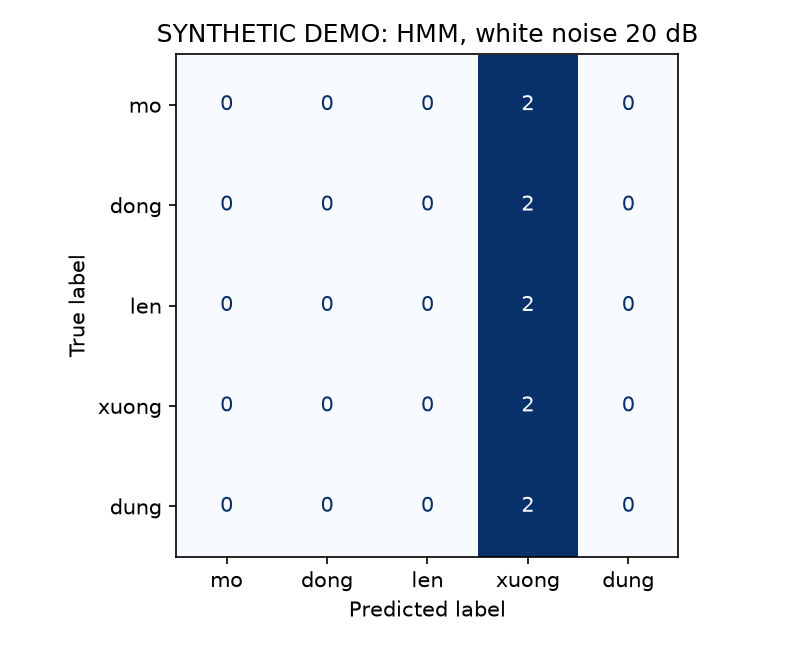

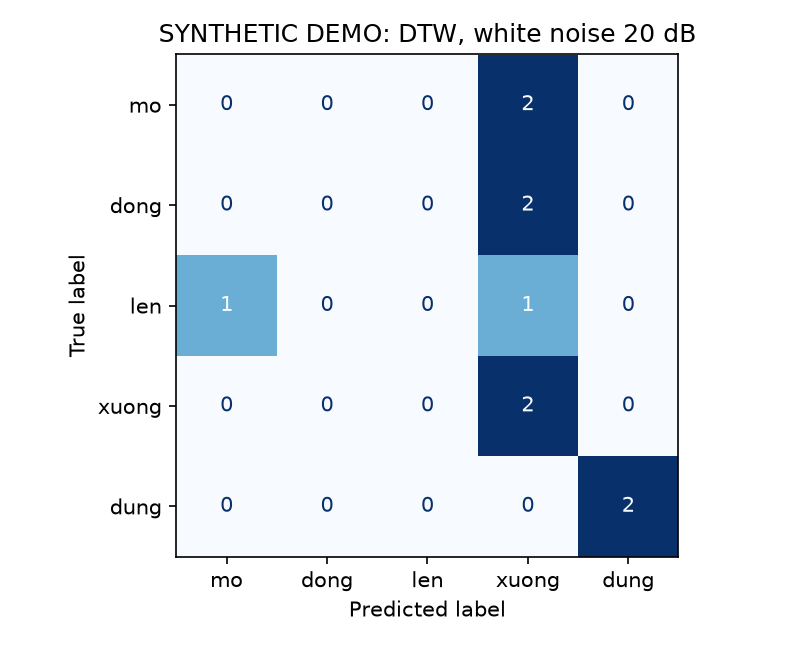

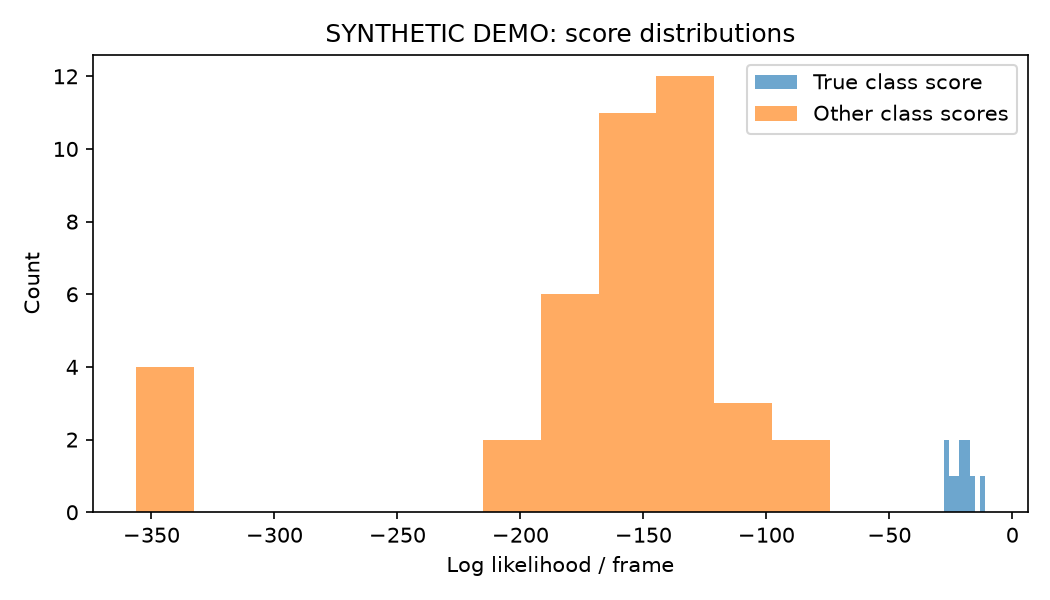

condition,file,truth,hmm,dtw,hmm_correct,dtw_correct
clean,mo_01.wav,mo,mo,mo,True,True
clean,mo_02.wav,mo,mo,mo,True,True
clean,dong_01.wav,dong,dong,dong,True,True
clean,dong_02.wav,dong,dong,dong,True,True
clean,len_01.wav,len,len,len,True,True
clean,len_02.wav,len,len,len,True,True
clean,xuong_01.wav,xuong,xuong,xuong,True,True
clean,xuong_02.wav,xuong,xuong,xuong,True,True
clean,dung_01.wav,dung,dung,dung,True,True
clean,dung_02.wav,dung,dung,dung,True,True


In [9]:
print('Noise:', summary['noise'])
print('Reject:', summary['reject'])
figure('cm_noise.png')
figure('cm_noise_dtw.png')
figure('score_distribution.png')
table('error_analysis.csv')


## Trả lời 10 câu hỏi phân tích
1. **Forward/Viterbi:** tổng so với max; Forward tính likelihood, Viterbi tìm state path tốt nhất.
2. **γ và ξ:** γ là trách nhiệm của state i với frame t; ξ là trách nhiệm của chuyển i→j giữa hai frame liên tiếp. Dùng các kỳ vọng này để cập nhật EM.
3. **Nghiệm Baum–Welch xấu:** khởi tạo không tốt, thiếu dữ liệu, quá nhiều state/tham số, phương sai suy biến hoặc mismatch. EM chỉ tìm nghiệm cục bộ; kiểm tra nhiều khởi tạo trên validation nếu dữ liệu cho phép.
4. **Diagonal covariance:** ít tham số hơn full, giảm nhu cầu dữ liệu và ổn định nghịch đảo/định thức; đánh đổi là bỏ tương quan giữa chiều.
5. **Delta:** HMM chuẩn giả định emission độc lập có điều kiện theo state, nên delta thêm thông tin lân cận vào mỗi vector quan sát.
6. **Lexicon:** chưa cần với model whole-word trực tiếp; cần để ánh xạ từ sang phone/subword và nối các acoustic models.
7. **Nói chậm:** self-loop cho phép ở lại state nhiều frame, kéo dài duration; duration ngầm theo phân bố hình học, chưa mô tả mọi biến thiên tốc độ.
8. **Chia T:** không cần để argmax các model trên cùng utterance vì T là hằng số chung; hữu ích khi so score khác utterance.
9. **Hai alignment:** DTW nối frame test với frame template; Viterbi nối frame quan sát với state model, không phải frame của một mẫu cụ thể.
10. **Unknown:** argmax bắt buộc trả nhãn; thêm ngưỡng top-1/frame và/hoặc margin, hiệu chỉnh trên validation known/unknown riêng, đo false reject và false accept.


## Phân tích định lượng và kết luận của lần chạy

In [10]:
display(Markdown((OUTPUT/'ANALYSIS.md').read_text(encoding='utf-8')))

# Kết quả thực nghiệm Lab 3

**Dữ liệu:** synthetic_espeak_ng
**Không phải đánh giá trên giọng người thật** nếu dùng dataset_demo. Tất cả số liệu dưới đây được tính từ lần chạy hiện tại.

## E1–E2: số trạng thái và đặc trưng

| States | Chiều | Train | Validation | Test | Chạm 80 vòng |
|---|---|---|---|---|---|
| 3 | 39 | 100% | 100% | 100% | 0 |
| 5 | 39 | 100% | 100% | 100% | 0 |
| 7 | 39 | 100% | 100% | 100% | 0 |
| 5 | 13 | 100% | 100% | 100% | 0 |

Cấu hình chính 5-state/39D được ấn định trước. Validation lấy 2 file cuối mỗi lớp từ train; test chỉ dùng báo cáo. Với 10 test utterance, một lỗi tương ứng 10 điểm phần trăm; không đủ để kết luận một cấu hình tối ưu phổ quát.
Nếu train cao hơn validation/test: có dấu hiệu overfit hoặc lệch phân bố. Nếu cả train lẫn validation thấp: xem lại đặc trưng, khởi tạo và khả năng underfit. Chạm giới hạn vòng lặp không đồng nghĩa hội tụ; xem final_gain và objective_decreases trong convergence.json.

## E3: covariance

Skipped: only 6 utterances/class; 780 covariance parameters/state at 39D vs 39 diagonal.

## E4: DTW và HMM

| Phương pháp | Accuracy | Fit (s) | Score/trial (ms) |
|---|---|---|---|
| HMM39 | 100% | 0.040 | 0.673 |
| DTW13 | 100% | 0.000 | 1.960 |
| DTW39 | 100% | 0.000 | 2.207 |

Thời gian score đã loại trích đặc trưng và JIT warm-up cho cả hai phương pháp. DTW chỉ lưu template nên thời gian ước lượng tham số bằng 0; đây không phải tổng latency end-to-end. DTW13 là baseline MFCC; DTW39 giúp kiểm soát khác biệt số chiều.
HMM nén mỗi lớp thành phân bố theo trạng thái; DTW đối sánh mọi template nên chi phí tăng theo số mẫu. Xem learning_curve.csv cho 1, 3, 6 mẫu/lớp.

Ví dụ quan sát: noise20dB, dung_01.wav; nhãn dung, HMM → xuong, DTW → dung. Khác biệt cho thấy mô hình phân bố và đối sánh template phản ứng khác nhau với chuỗi này. Tác động của duration, delta và nhiễu là giả thuyết cần thêm ablation, không suy ra nguyên nhân duy nhất từ một mẫu.

## E5: robustness

Nhiễu trắng 20 dB: HMM 20%; DTW 40%. Nhiễu được thêm vào waveform trước endpoint/MFCC. Cùng nhiễu và seed cho hai phương pháp. Đây là một loại mismatch, không đại diện người nói mới hoặc phòng thu khác.

## E6: LM và lexicon

lm_reranking.csv chọn utterance có acoustic margin nhỏ nhất; thử các context giả định và λ = 0, 0.1, 0.3, 1.0. Không có context thật nên không báo LM accuracy. Score/frame + λ log P là re-ranking có trọng số, không phải MAP nguyên bản nếu λ tùy chọn. lm_controlled_example.csv là điểm âm học giả lập riêng để phân tích cơ chế; nếu nhãn thật là len thì prior ủng hộ len giúp, nếu nhãn thật là xuong thì cùng prior có thể làm sai. Không tính ví dụ giả lập vào accuracy âm thanh.
Đếm mẫu số bằng số bigram đi ra từ context; không dùng tổng unigram gồm cả từ cuối câu. Vì không mô hình EOS, tổng xác suất trên đúng 5 lệnh bằng 1 cả với context chưa gặp.

## Viterbi, Forward và reject

forward_viterbi.csv đối chiếu DP viết riêng với thư viện trên hai utterance. Forward cộng mọi đường; Viterbi lấy đường tốt nhất. Duration ≈ số frame × 10 ms; state không có nhãn phone. Hai heatmap dùng chung tham số; cường độ và nhịp biến đổi khác nhau phản ánh các tín hiệu được tổng hợp khác nhau, không phải bằng chứng trực tiếp về khác biệt phone.
Ngưỡng reject đề xuất -49.657 log-likelihood/frame từ inner-validation. Có 0 test từ đã biết bị reject. Chưa có unknown test nên chưa đo FAR. Sau fit lại full train, cần hiệu chỉnh ngưỡng bằng tập calibration riêng vì thang score có thể đổi.

## Kết luận

Pipeline đã chạy đủ từ WAV đến đặc trưng, HMM, Viterbi, DTW và LM minh họa. Để kết luận về nhận dạng tiếng Việt trên người thật cần thu âm độc lập và chạy lại. Lexicon/corpus cần thay bằng bản giảng viên nếu được yêu cầu.

## Kiểm thử tự động
Kiểm tra Forward/Viterbi với vét cạn, chống underflow, DTW, đặc trưng, topology sau fit, bigram chuẩn hóa, parser và tính độc lập của file trong hai split. Đây là kiểm thử phần mềm; không thay cho đánh giá nhận dạng trên người thật.

In [11]:
import unittest
import test_lab3
suite=unittest.defaultTestLoader.loadTestsFromModule(test_lab3)
test_result=unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()


test_bigram_normalizes_including_terminal_word_context (test_lab3.LabTests.test_bigram_normalizes_including_terminal_word_context) ... ok
test_demo_split_and_audio_format (test_lab3.LabTests.test_demo_split_and_audio_format) ... ok
test_dtw_identical_and_stretched (test_lab3.LabTests.test_dtw_identical_and_stretched) ... ok
test_forward_viterbi_against_exhaustive_enumeration (test_lab3.LabTests.test_forward_viterbi_against_exhaustive_enumeration) ... ok
test_hmm_topology_and_score_reference (test_lab3.LabTests.test_hmm_topology_and_score_reference) ... ok
test_lexicon_duplicate_rejected (test_lab3.LabTests.test_lexicon_duplicate_rejected) ... ok
test_long_sequence_does_not_underflow (test_lab3.LabTests.test_long_sequence_does_not_underflow) ... ok
test_mfcc_cmvn_and_dimensionality (test_lab3.LabTests.test_mfcc_cmvn_and_dimensionality) ... ok
test_silence_and_short_audio_rejected (test_lab3.LabTests.test_silence_and_short_audio_rejected) ... ok

-----------------------------------------

## Nguồn và bàn giao
- Đề Lab 3.pdf, CSE457, Trường Đại học Thủy Lợi, do người dùng cung cấp.
- [hmmlearn 0.3.3](https://hmmlearn.readthedocs.io/en/0.3.3/tutorial.html).
- [librosa 0.11](https://librosa.org/doc/0.11.0/).
- [eSpeak NG](https://github.com/espeak-ng/espeak-ng) và [espeakng-loader](https://github.com/thewh1teagle/espeakng-loader).

Xem README để chạy lại, thu âm và đưa dự án lên Git. Dữ liệu tổng hợp và lexicon/corpus minh họa cần được giảng viên chấp nhận hoặc thay bằng dữ liệu yêu cầu trước khi nộp chính thức.